# Investigação do KNN (autor: marina)

Notebook de investigação do `KNeighborsClassifier`, comparável com os demais modelos do grupo:
mesma tabela `features`, mesma divisão (treino 2021–2022, validação 2023), mesmos folds
temporais (`src/modelagem/validacao.py`), mesmas métricas (PR-AUC principal, Recall@50,
Recall@100, ROC-AUC; `ARCHITECTURE.md`, seção 5) e semente 42. Todas as funções de treino e
avaliação vêm de `src.modelagem.treino` e `src.modelagem.pipeline`; o que é novo fica aqui.

Regras deste notebook:

- O **teste de 2024 não é usado** aqui, nem para olhar: a parte `teste` é descartada logo no setup.
  Ele pertence só ao `registrar_campeao` oficial.
- A melhor configuração é escolhida pelo **PR-AUC médio da CV temporal**. A validação de 2023 é
  reportada, mas não escolhe hiperparâmetro.
- Todo run no MLflow leva as tags `autor=marina` e `modelo=knn`. Os pisos (Regressão Logística
  padrão e heurística de recorrência) são calculados aqui **sem** registrar runs, para não duplicar
  os runs oficiais do experimento `01_baseline`.
- O pré-processamento é o do repositório (`montar_pipeline`): mediana + `StandardScaler` nas
  numéricas e one-hot nas categóricas. A escala importa para o KNN, porque a distância euclidiana
  soma todas as colunas.

Execução (dentro do container, como os notebooks 01 e 02):

```bash
docker compose --profile dev run --rm -T -v "$PWD/reports:/app/reports" -w /app/notebooks jupyter \
    jupyter nbconvert --to notebook --execute --inplace modelo_knn.ipynb --ExecutePreprocessor.timeout=-1
```

## 1. Setup

In [1]:
from pathlib import Path
import sys
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 180, "display.max_columns", 40, "display.precision", 3)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "grid.alpha": .3})

# O notebook roda de notebooks/ (Jupyter ou nbconvert); os dados ficam em ../data.
RAIZ = Path.cwd().parent if (Path.cwd().parent / "data").exists() else Path("/app")
sys.path.insert(0, str(RAIZ))

import mlflow
from sklearn.base import clone
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold

from src.modelagem import metricas
from src.modelagem import treino as T
from src.modelagem.pipeline import SEMENTE, montar_pipeline, modelos
from src.modelagem.treino import (ESPACOS, _cv, _cv_estratificado, _dados, _parametros, _rodar, _xy,
                                  carregar_features, score_heuristica)

MODELO, AUTOR = "knn", "marina"
TAGS = {"autor": AUTOR, "modelo": MODELO}
ALVO = "y_vitima"
FIG = RAIZ / "reports" / "figuras" / MODELO
EXP = RAIZ / "reports" / "experimentos"
FIG.mkdir(parents=True, exist_ok=True)
EXP.mkdir(parents=True, exist_ok=True)

T._mlflow()
print("MLflow:", mlflow.get_tracking_uri(), "| semente:", SEMENTE)

/usr/local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


MLflow: http://mlflow:5000 | semente: 42


In [2]:
# src.modelagem.metricas troca o backend para Agg (feito para o container sem display); de volta ao inline
%matplotlib inline


def salvar(fig, nome):
    """Grava a figura em reports/figuras/knn/ e mostra no notebook."""
    fig.tight_layout()
    fig.savefig(FIG / nome, dpi=110)
    plt.show()

In [3]:
features = carregar_features()


def preparar(alvo):
    """Partes e folds do alvo, sem a parte de teste (2024 não é usado neste notebook)."""
    _, partes, folds = _dados(alvo, features)
    partes = {k: v for k, v in partes.items() if k != "teste"}
    return partes, folds


partes, folds = preparar(ALVO)
Xtr, ytr = _xy(partes["treino"], ALVO)
Xv, yv = _xy(partes["validacao"], ALVO)
tri_tr = partes["treino"]["trimestre"].to_numpy()
tri_v = partes["validacao"]["trimestre"]

resumo = pd.DataFrame({
    nome: {"linhas": len(p), "local_id": p["local_id"].nunique(),
           "trimestres": f"{p['trimestre'].min()}–{p['trimestre'].max()}",
           "positivos": int(p[ALVO].sum()), "prevalência": round(p[ALVO].mean(), 4)}
    for nome, p in partes.items()}).T
display(resumo)
print("colunas de entrada:", Xtr.shape[1], "| colunas depois do pré-processamento:",
      montar_pipeline(features, MODELO).named_steps["prep"].fit(Xtr).transform(Xtr.head()).shape[1])
print("folds temporais:", [(f"{tri_tr[tr].min()}–{tri_tr[tr].max()}", tri_tr[te][0]) for tr, te in folds])
print("prevalência na validação de cada fold:", [round(ytr.iloc[te].mean(), 3) for _, te in folds])

,linhas,local_id,trimestres,positivos,prevalência
treino,13384,1673,2021Q1–2022Q4,1989,0.149
validacao,6692,1673,2023Q1–2023Q4,1392,0.208


colunas de entrada: 48 | colunas depois do pré-processamento: 142
folds temporais: [('2021Q1–2021Q4', '2022Q1'), ('2021Q1–2022Q1', '2022Q2'), ('2021Q1–2022Q2', '2022Q3'), ('2021Q1–2022Q3', '2022Q4')]
prevalência na validação de cada fold: [np.float64(0.137), np.float64(0.167), np.float64(0.164), np.float64(0.155)]


## 2. Pisos: Regressão Logística padrão e heurística de recorrência

Os dois pisos do `ARCHITECTURE.md` (seções 6 e 17.9), medidos com as mesmas métricas, os mesmos
folds e a mesma validação, mas **sem registrar runs** (os runs oficiais ficam no `01_baseline`).

- Regressão Logística: `pipeline.modelos()["regressao_logistica"]` via `montar_pipeline`, com
  `_cv` (CV temporal) e `_cv_estratificado`.
- Heurística: `score_heuristica` (acidentes com vítima nos últimos 4 trimestres, com o total
  desempatando). Não treina nada: em cada fold, só é avaliada na parte de validação do fold.

Na validação de 2023, o limiar (para F1, precisão e recall) é o que maximiza o F1 na própria
validação (`metricas.escolher_limiar`), como no `_rodar`. PR-AUC, Recall@k e ROC-AUC não dependem
do limiar.

In [4]:
def em_validacao(y, score, trimestre):
    """Métricas da seção 5 na validação, como o _rodar calcula (limiar pelo F1)."""
    score = np.asarray(score, dtype=float)
    return metricas.avaliar(y, score, trimestre, metricas.escolher_limiar(y, score))


def cv_score_fixo(score, y, splits, prefixo):
    """CV de um score que não treina (heurística): métricas só na parte de validação de cada fold."""
    ap = np.array([average_precision_score(y.iloc[te], score.iloc[te]) for _, te in splits])
    roc = np.array([roc_auc_score(y.iloc[te], score.iloc[te]) for _, te in splits])
    # std com ddof=0, como o .std() do numpy que o _cv usa
    return {f"{prefixo}_pr_auc_mean": ap.mean(), f"{prefixo}_pr_auc_std": ap.std(),
            f"{prefixo}_roc_auc_mean": roc.mean(), f"{prefixo}_roc_auc_std": roc.std()}


def linha(cv, m_val, run_id=None):
    return {**cv, **{f"val_{k}": v for k, v in m_val.items()}, "run_id": run_id}


def pisos(alvo, partes, folds):
    Xtr, ytr = _xy(partes["treino"], alvo)
    Xv, yv = _xy(partes["validacao"], alvo)
    tri_v = partes["validacao"]["trimestre"]
    saida = {}
    lr = montar_pipeline(features, "regressao_logistica")
    cv = {**_cv(lr, Xtr, ytr, folds), **_cv_estratificado(lr, Xtr, ytr)}
    saida["regressao_logistica"] = linha(cv, em_validacao(yv, clone(lr).fit(Xtr, ytr).predict_proba(Xv)[:, 1], tri_v))
    s_tr = score_heuristica(partes["treino"])
    estrat = list(StratifiedKFold(5, shuffle=True, random_state=SEMENTE).split(Xtr, ytr))
    cv = {**cv_score_fixo(s_tr, ytr, folds, "cv_temporal"), **cv_score_fixo(s_tr, ytr, estrat, "cv_estratificado")}
    saida["heuristica_recorrencia"] = linha(cv, em_validacao(yv, score_heuristica(partes["validacao"]), tri_v))
    return saida


resultados = {}  # (alvo, nome) -> métricas
t0 = time.time()
for nome, r in pisos(ALVO, partes, folds).items():
    resultados[(ALVO, nome)] = r
print(f"pisos calculados em {time.time() - t0:.1f} s")

pisos calculados em 34.1 s


## 3. KNN padrão (experimento `02_comparacao_modelos`)

Hiperparâmetros de `pipeline.modelos()["knn"]`: `n_neighbors=50`, `weights="distance"` (o resto é
o padrão do scikit-learn: distância euclidiana, `algorithm="auto"`). Um run via `T._rodar` com CV
temporal, CV estratificado e validação de 2023, mais a curva de aprendizado nos 2 maiores folds,
como na `comparar_modelos` oficial.

O score do KNN é a fração (ponderada ou não) de vizinhos positivos. Com `weights="uniform"` e
k vizinhos, ele só pode assumir k + 1 valores, e muitos locais empatam. Empates no topo da lista
deixam o Recall@k dependente da ordem em que as linhas estão na tabela. Por isso, além das métricas,
conto os valores distintos de score, o maior grupo de empatados e quantas linhas empatam com o
50º colocado de cada trimestre.

In [5]:
def empates(score, trimestre, k=50):
    """Valores distintos de score, maior grupo empatado e, por trimestre, quantas linhas têm
    exatamente o score do k-ésimo colocado (empate no corte do Recall@k)."""
    s = np.round(np.asarray(score, dtype=float), 10)
    valores, contagem = np.unique(s, return_counts=True)
    no_corte = []
    for t in pd.unique(np.asarray(trimestre)):
        st = s[np.asarray(trimestre) == t]
        no_corte.append(int((st == np.sort(st)[::-1][k - 1]).sum()))
    return {"scores distintos": len(valores), "maior grupo empatado": int(contagem.max()),
            "score do maior grupo": float(valores[contagem.argmax()]),
            f"empatados com o {k}º (média por trimestre)": float(np.mean(no_corte))}


mlflow.set_experiment(T.EXPERIMENTOS["comparacao"])
pipe_padrao = montar_pipeline(features, MODELO)
print(pipe_padrao.named_steps["modelo"])
t0 = time.time()
extras = {**_cv(pipe_padrao, Xtr, ytr, folds), **_cv_estratificado(pipe_padrao, Xtr, ytr)}
run_padrao, m_padrao = _rodar(f"{MODELO}_padrao", ALVO, pipe_padrao, partes, _parametros(pipe_padrao), extras,
                              {"etapa": "comparacao", **TAGS}, folds)
resultados[(ALVO, "knn_padrao")] = linha(extras, m_padrao, run_padrao)
print(f"run {run_padrao} em {time.time() - t0:.1f} s")
print("algoritmo de busca de vizinhos escolhido pelo 'auto':", pipe_padrao.named_steps["modelo"]._fit_method)
score_padrao = pipe_padrao.predict_proba(Xv)[:, 1]
print(f"empates na validação ({len(Xv)} linhas):", empates(score_padrao, tri_v))
print("para comparar, heurística de recorrência:", empates(score_heuristica(partes["validacao"]), tri_v))

KNeighborsClassifier(n_neighbors=50, weights='distance')


2026/11/23 14:31:59 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


🏃 View run knn_padrao at: http://mlflow:5000/#/experiments/1/runs/07b767d353144ac4b0423befc8ae0854
🧪 View experiment at: http://mlflow:5000/#/experiments/1
run 07b767d353144ac4b0423befc8ae0854 em 13.3 s
algoritmo de busca de vizinhos escolhido pelo 'auto': brute


empates na validação (6692 linhas): {'scores distintos': 6117, 'maior grupo empatado': 574, 'score do maior grupo': 0.0, 'empatados com o 50º (média por trimestre)': 1.0}
para comparar, heurística de recorrência: {'scores distintos': 154, 'maior grupo empatado': 3898, 'score do maior grupo': 0.0, 'empatados com o 50º (média por trimestre)': 3.5}


**Leitura.** O `algorithm="auto"` escolheu a busca `brute` (com 142 colunas densas depois do one-hot,
o scikit-learn não usa árvores KD/Ball). O run completo levou 13 s. Com `weights="distance"`, o score
quase não empata: são 6.117 valores distintos em 6.692 linhas da validação. O maior grupo empatado
(574 linhas) tem score 0, ou seja, são locais sem nenhum positivo entre os 50 vizinhos, e fica no
fim da lista, longe do corte do Recall@k. No 50º colocado de cada trimestre, só 1 linha tem aquele
score (nenhum empate no corte). A heurística, para comparar, tem 154 valores distintos e 3.898
linhas empatadas em 0, com 3,5 linhas em média empatadas no 50º. Então, no KNN padrão, o Recall@k
não é afetado por empates.

## 4. Tabela 1: pisos e KNN padrão (`y_vitima`)

In [6]:
NOMES = {"heuristica_recorrencia": "Heurística de recorrência", "regressao_logistica": "Regressão Logística padrão",
         "knn_padrao": "KNN padrão", "knn_otimizado": "KNN otimizado (Optuna 40)"}


def tabela(alvo, nomes):
    linhas = {}
    for n in nomes:
        r = resultados[(alvo, n)]
        linhas[NOMES[n]] = {
            "CV temporal PR-AUC": f"{r['cv_temporal_pr_auc_mean']:.3f} ± {r['cv_temporal_pr_auc_std']:.3f}",
            "CV temporal ROC-AUC": f"{r['cv_temporal_roc_auc_mean']:.3f} ± {r['cv_temporal_roc_auc_std']:.3f}",
            "CV estratificado PR-AUC": f"{r['cv_estratificado_pr_auc_mean']:.3f} ± {r['cv_estratificado_pr_auc_std']:.3f}",
            "Δ PR-AUC estrat. − temporal": f"{r['cv_estratificado_pr_auc_mean'] - r['cv_temporal_pr_auc_mean']:+.3f}",
            "Val PR-AUC": f"{r['val_pr_auc']:.3f}",
            "Val Recall@50": f"{r['val_recall_at_50']:.3f}",
            "Val Recall@100": f"{r['val_recall_at_100']:.3f}",
            "Val ROC-AUC": f"{r['val_roc_auc']:.3f}",
        }
    return pd.DataFrame(linhas).T


tabela1 = tabela(ALVO, ["heuristica_recorrencia", "regressao_logistica", "knn_padrao"])
print(f"prevalência (PR-AUC de um ranking aleatório): treino {ytr.mean():.3f} | validação {yv.mean():.3f}")
tabela1

prevalência (PR-AUC de um ranking aleatório): treino 0.149 | validação 0.208


,CV temporal PR-AUC,CV temporal ROC-AUC,CV estratificado PR-AUC,Δ PR-AUC estrat. − temporal,Val PR-AUC,Val Recall@50,Val Recall@100,Val ROC-AUC
Heurística de recorrência,0.560 ± 0.023,0.790 ± 0.016,0.541 ± 0.021,-0.019,0.614,0.141,0.261,0.795
Regressão Logística padrão,0.597 ± 0.023,0.816 ± 0.017,0.578 ± 0.020,-0.019,0.658,0.141,0.264,0.818
KNN padrão,0.597 ± 0.020,0.823 ± 0.013,0.573 ± 0.026,-0.024,0.656,0.139,0.258,0.827


**Leitura da Tabela 1.**

- **O KNN padrão empata com a Regressão Logística.** O PR-AUC na CV temporal é 0,597 ± 0,020 contra
  0,597 ± 0,023. Na validação de 2023, é 0,656 contra 0,658. As diferenças ficam muito abaixo do
  desvio entre folds (~0,02). O KNN tem o maior ROC-AUC dos três (0,823 na CV e 0,827 na
  validação), mas o Recall@50 (0,139) e o Recall@100 (0,258) ficam no nível dos pisos (0,141 e
  0,261 a 0,264).
- **Contra a heurística de recorrência**, o KNN padrão ganha +0,037 de PR-AUC na CV temporal (0,597
  contra 0,560) e +0,042 na validação (0,656 contra 0,614). O Recall@k praticamente empata.
- **Temporal × estratificado: sem inflação.** O k-fold estratificado dá um PR-AUC *menor* que a CV
  temporal nos três casos (−0,019, −0,019 e −0,024). No KNN, a expectativa era de inflação: no
  k-fold estratificado, os outros trimestres do mesmo local, inclusive os futuros, ficam no treino e
  podem ser vizinhos. Isso não aparece. A heurística, que não treina nada, mostra a mesma diferença,
  o que aponta para a prevalência dos trimestres validados (15,6% em média nos folds temporais,
  contra 14,9% no treino inteiro), e não para vazamento.
- O PR-AUC da validação fica acima do da CV em todos os modelos, junto com a prevalência maior de
  2023 (0,208). PR-AUC só deve ser comparado entre modelos dentro da mesma parte.

## 5. Busca de hiperparâmetros: Optuna com 40 trials (experimento `03_otimizacao_hiperparametros`)

Mesmo espaço do repositório, `T.ESPACOS["knn"]`: `n_neighbors` de 10 a 300 (inteiro, escala log)
e `weights` em `uniform` ou `distance`. `TPESampler(seed=42)`, objetivo `cv_temporal_pr_auc_mean`
calculado pelo próprio `_cv` com os folds temporais. A validação de 2023 não entra na escolha.

Os trials **não** viram runs: todos vão para um DataFrame (e para
`reports/experimentos/marina_knn_trials_optuna.csv`), e só o melhor é registrado no MLflow, via
`T._rodar`, com `busca=optuna_40`. Limite de tempo: 30 minutos (`timeout` do Optuna). Se ele
cortar a busca, o motivo é impresso.

In [7]:
import optuna

optuna.logging.set_verbosity(optuna.logging.WARNING)
N_TRIALS, LIMITE_S = 40, 30 * 60


def objetivo(trial):
    params = ESPACOS[MODELO](trial)
    cv = _cv(montar_pipeline(features, MODELO, **params), Xtr, ytr, folds)
    for k, v in cv.items():
        trial.set_user_attr(k, v)
    return cv["cv_temporal_pr_auc_mean"]


def estudar(n_trials, timeout=None):
    estudo = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEMENTE))
    t0 = time.time()
    estudo.optimize(objetivo, n_trials=n_trials, timeout=timeout)
    return estudo, time.time() - t0


estudo, tempo_busca = estudar(N_TRIALS, LIMITE_S)
n_feitos = len(estudo.trials)
print(f"Optuna: {n_feitos} trials em {tempo_busca:.1f} s ({tempo_busca / 60:.2f} min)")
if n_feitos < N_TRIALS:
    print(f"MOTIVO: o limite de {LIMITE_S / 60:.0f} min cortou a busca em {n_feitos} trials.")

trials = estudo.trials_dataframe(attrs=("number", "value", "params", "user_attrs", "duration"))
trials.columns = [c.removeprefix("params_").removeprefix("user_attrs_") for c in trials.columns]
trials["duracao_s"] = trials.pop("duration").dt.total_seconds()
trials["melhor_acumulado"] = trials["value"].cummax()
trials.to_csv(EXP / "marina_knn_trials_optuna.csv", index=False)
print("combinações distintas testadas:", trials[["n_neighbors", "weights"]].drop_duplicates().shape[0])
cols = ["number", "value", "cv_temporal_pr_auc_std", "cv_temporal_roc_auc_mean", "n_neighbors", "weights", "duracao_s"]
trials.sort_values("value", ascending=False)[cols].head(10)

Optuna: 40 trials em 45.6 s (0.76 min)
combinações distintas testadas: 40


,number,value,cv_temporal_pr_auc_std,cv_temporal_roc_auc_mean,n_neighbors,weights,duracao_s
31,31,0.605,0.020,0.826,221,distance,1.183
10,10,0.605,0.020,0.824,288,distance,1.295
13,13,0.605,0.019,0.826,117,distance,1.143
3,3,0.605,0.018,0.826,110,distance,1.176
32,32,0.604,0.020,0.826,240,distance,1.226
33,33,0.604,0.020,0.826,227,distance,1.145
25,25,0.604,0.020,0.826,204,distance,1.204
14,14,0.604,0.021,0.827,189,distance,1.226
17,17,0.604,0.020,0.824,283,distance,1.306
11,11,0.604,0.019,0.824,270,distance,1.360


In [8]:
melhor = estudo.best_trial
params_melhor = dict(melhor.params)
print(f"melhor trial: #{melhor.number} | CV temporal PR-AUC {melhor.value:.4f} | {params_melhor}")

mlflow.set_experiment(T.EXPERIMENTOS["otimizacao"])
pipe_otim = montar_pipeline(features, MODELO, **params_melhor)
extras_otim = {**_cv(pipe_otim, Xtr, ytr, folds), **_cv_estratificado(pipe_otim, Xtr, ytr)}
run_otim, m_otim = _rodar(f"{MODELO}_optuna40_melhor", ALVO, pipe_otim, partes, params_melhor, extras_otim,
                          {"etapa": "otimizacao", "busca": "optuna_40", **TAGS}, folds)
resultados[(ALVO, "knn_otimizado")] = linha(extras_otim, m_otim, run_otim)
print(f"run {run_otim} | validação 2023 PR-AUC {m_otim['pr_auc']:.4f} (só reportada)")

melhor trial: #31 | CV temporal PR-AUC 0.6050 | {'n_neighbors': 221, 'weights': 'distance'}


2026/11/23 14:33:03 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


🏃 View run knn_optuna40_melhor at: http://mlflow:5000/#/experiments/2/runs/8538cc787e3044b6b11af5dfc9f5ed94
🧪 View experiment at: http://mlflow:5000/#/experiments/2
run 8538cc787e3044b6b11af5dfc9f5ed94 | validação 2023 PR-AUC 0.6536 (só reportada)


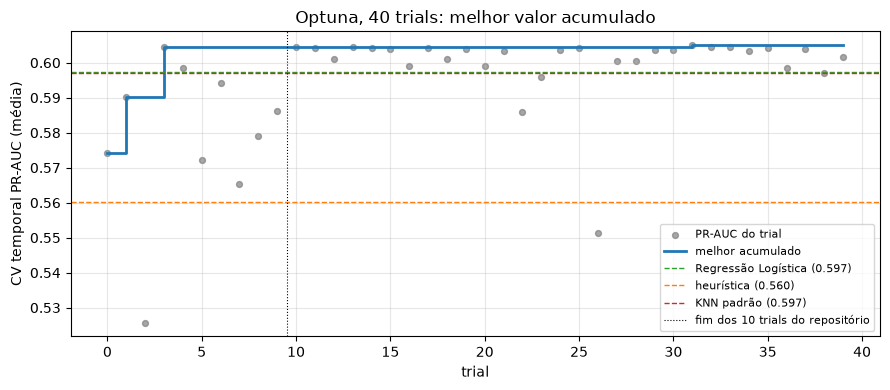

 number  value  melhor_acumulado
      0  0.574             0.574
      4  0.598             0.605
      9  0.586             0.605
     19  0.604             0.605
     29  0.604             0.605
     39  0.602             0.605


In [9]:
r_lr, r_h = resultados[(ALVO, "regressao_logistica")], resultados[(ALVO, "heuristica_recorrencia")]
r_pad = resultados[(ALVO, "knn_padrao")]
fig, ax = plt.subplots(figsize=(9, 4))
ax.scatter(trials["number"], trials["value"], s=18, color="gray", alpha=.7, label="PR-AUC do trial")
ax.step(trials["number"], trials["melhor_acumulado"], where="post", color="C0", lw=2, label="melhor acumulado")
for r, nome, cor in [(r_lr, "Regressão Logística", "C2"), (r_h, "heurística", "C1"), (r_pad, "KNN padrão", "C3")]:
    ax.axhline(r["cv_temporal_pr_auc_mean"], ls="--", lw=1, color=cor, label=f"{nome} ({r['cv_temporal_pr_auc_mean']:.3f})")
ax.axvline(9.5, color="k", lw=.8, ls=":", label="fim dos 10 trials do repositório")
ax.set(xlabel="trial", ylabel="CV temporal PR-AUC (média)", title="Optuna, 40 trials: melhor valor acumulado")
ax.legend(fontsize=8, loc="lower right")
salvar(fig, "optuna_melhor_acumulado.png")
print(trials[["number", "value", "melhor_acumulado"]].iloc[[0, 4, 9, 19, 29, n_feitos - 1]].to_string(index=False))

**Leitura.** A busca chega ao teto logo no começo. O trial 0 (k = 35, `uniform`) dá 0,574, e o
trial 3 (k = 110, `distance`) já dá 0,6045. O melhor dos 40 é o trial 31 (k = 221, `distance`), com
0,6050, só +0,0005 acima do trial 3. Os 10 melhores trials ficam todos entre 0,604 e 0,605, com k
de 110 a 288 e `weights="distance"`. O melhor valor fica +0,008 acima da Regressão Logística e do
KNN padrão (0,597) e +0,045 acima da heurística (0,560). O ganho sobre a Regressão Logística é
menor que o desvio entre folds (0,020), então, na CV temporal, os dois empatam.

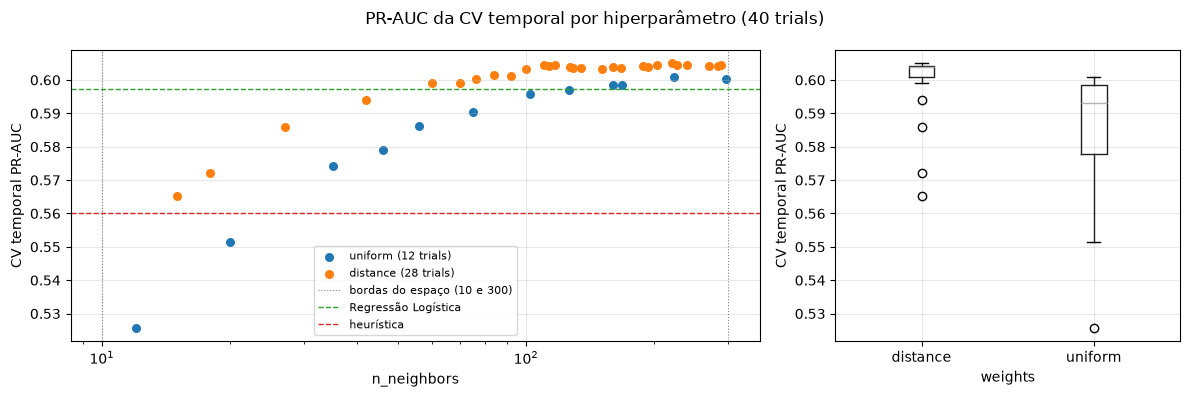

          count   mean    max
weights                      
distance     28  0.600  0.605
uniform      12  0.583  0.601

Spearman n_neighbors × PR-AUC, por weights: {'distance': np.float64(0.813), 'uniform': np.float64(0.986)}

melhor n_neighbors = 221: posição no espaço em escala log = 0.91 (0 = borda 10, 1 = borda 300)
trials com n_neighbors >= 250: 4 | com n_neighbors <= 12: 1


In [10]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [2, 1]})
for w, cor in [("uniform", "C0"), ("distance", "C1")]:
    t = trials[trials["weights"] == w]
    axs[0].scatter(t["n_neighbors"], t["value"], color=cor, s=30, label=f"{w} ({len(t)} trials)")
axs[0].axvline(10, color="gray", lw=.8, ls=":")
axs[0].axvline(300, color="gray", lw=.8, ls=":", label="bordas do espaço (10 e 300)")
axs[0].axhline(r_lr["cv_temporal_pr_auc_mean"], color="C2", ls="--", lw=1, label="Regressão Logística")
axs[0].axhline(r_h["cv_temporal_pr_auc_mean"], color="C3", ls="--", lw=1, label="heurística")
axs[0].set(xscale="log", xlabel="n_neighbors", ylabel="CV temporal PR-AUC")
axs[0].legend(fontsize=8)
trials.boxplot(column="value", by="weights", ax=axs[1])
axs[1].set(title="", xlabel="weights", ylabel="CV temporal PR-AUC")
fig.suptitle("PR-AUC da CV temporal por hiperparâmetro (40 trials)")
salvar(fig, "optuna_pr_auc_por_hiperparametro.png")
print(trials.groupby("weights")["value"].agg(["count", "mean", "max"]).round(4).to_string())
print("\nSpearman n_neighbors × PR-AUC, por weights:",
      {w: round(t["n_neighbors"].corr(t["value"], method="spearman"), 3) for w, t in trials.groupby("weights")})
k_melhor = params_melhor["n_neighbors"]
pos_log = (np.log(k_melhor) - np.log(10)) / (np.log(300) - np.log(10))
print(f"\nmelhor n_neighbors = {k_melhor}: posição no espaço em escala log = {pos_log:.2f} (0 = borda 10, 1 = borda 300)")
print("trials com n_neighbors >= 250:", int((trials["n_neighbors"] >= 250).sum()),
      "| com n_neighbors <= 12:", int((trials["n_neighbors"] <= 12).sum()))

**Leitura.**

- **`weights="distance"` é melhor em todo o espaço.** Ele tem média de 0,600 em 28 trials e máximo
  de 0,605, contra média de 0,583 e máximo de 0,601 do `uniform` em 12 trials. O TPE percebeu isso
  cedo e concentrou 70% dos trials em `distance`.
- **Quanto maior o k, melhor, até um platô.** O Spearman entre `n_neighbors` e PR-AUC é +0,81
  (`distance`) e +0,99 (`uniform`). Mas, com `distance`, a curva fica plana a partir de k ≈ 100:
  todos os trials com k entre 100 e 288 dão de 0,603 a 0,605.
- **Borda do espaço:** o melhor k (221) fica na parte de cima do espaço, a 0,91 do caminho entre 10
  e 300 em escala log. Não está colado na borda de 300, mas está perto dela. Os trials mais próximos
  da borda (k = 270, 283 e 288) dão de 0,6042 a 0,6045, praticamente o mesmo valor. Como a curva já
  está plana ali, é pouco provável que k > 300 mude o resultado de forma relevante, mas isso não
  foi testado: o espaço é o do repositório e não foi ampliado.

### Valeu ampliar de 10 para 40 trials?

O repositório usa 10 trials (`T.N_TRIALS`, seção 17.5). Rodo um estudo separado de 10 trials, com
a mesma semente e o mesmo objetivo, para comparar com os 40. A validação de 2023 dos dois melhores
é só reportada, sem registro no MLflow.

In [11]:
estudo10, tempo10 = estudar(10)
pipe10 = montar_pipeline(features, MODELO, **estudo10.best_params)
m10 = em_validacao(yv, clone(pipe10).fit(Xtr, ytr).predict_proba(Xv)[:, 1], tri_v)
comparacao_busca = pd.DataFrame({
    "10 trials (padrão do repositório)": {"tempo (s)": tempo10, "melhor trial": estudo10.best_trial.number,
                                          "CV temporal PR-AUC": estudo10.best_value, "Val PR-AUC": m10["pr_auc"],
                                          "Val Recall@50": m10["recall_at_50"], "params": estudo10.best_params},
    "40 trials": {"tempo (s)": tempo_busca, "melhor trial": melhor.number, "CV temporal PR-AUC": melhor.value,
                  "Val PR-AUC": m_otim["pr_auc"], "Val Recall@50": m_otim["recall_at_50"], "params": params_melhor},
}).T
print("os 10 primeiros trials dos 40 coincidem com o estudo de 10:",
      np.allclose(trials["value"].iloc[:10], [t.value for t in estudo10.trials]))
print(f"ganho de CV temporal PR-AUC com 40 trials: {melhor.value - estudo10.best_value:+.4f}")
comparacao_busca

os 10 primeiros trials dos 40 coincidem com o estudo de 10: True
ganho de CV temporal PR-AUC com 40 trials: +0.0005


,tempo (s),melhor trial,CV temporal PR-AUC,Val PR-AUC,Val Recall@50,params
10 trials (padrão do repositório),10.234,3,0.605,0.654,0.139,"{'n_neighbors': 110, 'weights': 'distance'}"
40 trials,45.593,31,0.605,0.654,0.14,"{'n_neighbors': 221, 'weights': 'distance'}"


**Leitura: ampliar para 40 trials não valeu.** Com a mesma semente, os 10 primeiros trials dos 40
são idênticos ao estudo de 10. O estudo de 10 acha o seu melhor no trial 3 (k = 110, `distance`,
0,6045). Os 40 trials trocam para k = 221 e ganham +0,0005 na CV temporal, 40 vezes menos que o
desvio entre folds (0,020). Na validação de 2023, as duas configurações dão o mesmo PR-AUC (0,654)
e o mesmo Recall@50 (0,139 e 0,140). O custo foi 4,5 vezes maior: 45,6 s contra 10,2 s. A busca
inteira ficou muito abaixo do limite de 30 minutos, então não foi preciso reduzir os trials.

## 6. Diagnóstico da melhor configuração

Curva de aprendizado com `metricas.curva_aprendizado` nos 4 folds temporais (fatias de 33%, 66% e
100% do treino de cada fold), e PR-AUC no próprio treino × CV temporal × validação 2023.

**Cuidado com o PR-AUC no treino do KNN.** Ao prever o próprio treino, cada linha é vizinha de si
mesma, a distância zero. Com `weights="distance"`, o scikit-learn dá peso 1 aos vizinhos a
distância zero e peso 0 a todos os outros, então o score da linha vira o próprio rótulo, e o PR-AUC
fica perto de 1 por construção. Com `weights="uniform"`, o próprio ponto é 1 voto entre k, e o
efeito é menor, mas ainda existe. Esse número não mede overfitting. Por isso, junto dele calculo um
**PR-AUC no treino sem o próprio ponto** (*leave-self-out*: os k vizinhos mais próximos excluindo a
linha consultada), que é a comparação honesta de "treino × validação" para o KNN.

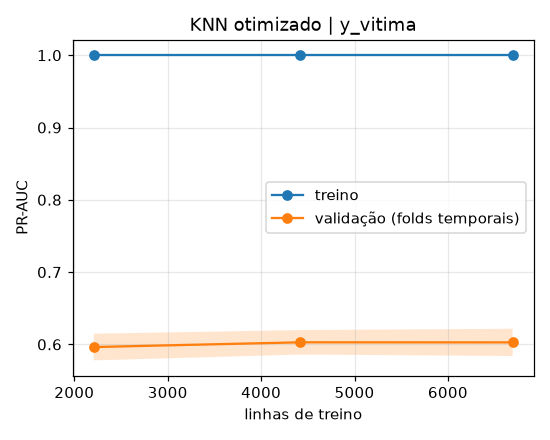

,linhas de treino,treino (média),validação dos folds (média),validação (desvio)
0,2208,1.0,0.596,0.018
1,4416,1.0,0.603,0.017
2,6692,1.0,0.603,0.019


In [12]:
from sklearn.model_selection import learning_curve

titulo_otim = f"KNN otimizado | {ALVO}"
metricas.curva_aprendizado(clone(pipe_otim), Xtr, ytr, folds, FIG / "curva_aprendizado.png", titulo_otim)
display(Image(FIG / "curva_aprendizado.png"))
# os mesmos números da figura, para a leitura
tam, s_tr, s_va = learning_curve(clone(pipe_otim), Xtr, ytr, cv=folds, train_sizes=[0.33, 0.66, 1.0],
                                 scoring="average_precision", n_jobs=1)
pd.DataFrame({"linhas de treino": tam, "treino (média)": s_tr.mean(1), "validação dos folds (média)": s_va.mean(1),
              "validação (desvio)": s_va.std(1)}).round(3)

**Leitura.** A curva de treino fica em **1,000** em todos os tamanhos. Isso é o efeito descrito
acima, e não overfitting: com `weights="distance"`, cada linha do treino é vizinha de si mesma a
distância zero, e o score dela vira o próprio rótulo. A curva que importa é a de validação dos
folds: 0,596 → 0,603 → 0,603 (desvio ~0,018). Ela sobe pouco de 2.208 para 4.416 linhas e para de
subir depois. Com estas features, mais linhas do mesmo período ajudam pouco o KNN. O eixo x vai até
6.692 linhas porque o `learning_curve` usa como teto o menor treino entre os folds (4 trimestres).

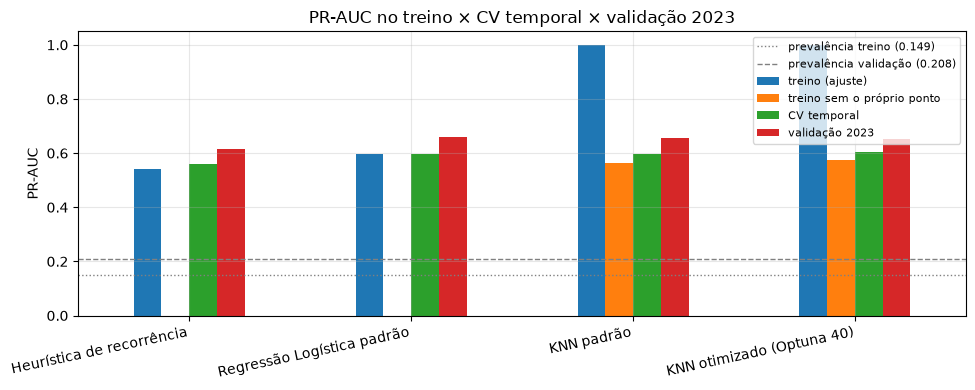

,treino (ajuste),treino sem o próprio ponto,CV temporal,validação 2023
Heurística de recorrência,0.540,NaN,0.560,0.614
Regressão Logística padrão,0.595,NaN,0.597,0.658
KNN padrão,1.000,0.565,0.597,0.656
KNN otimizado (Optuna 40),1.000,0.576,0.605,0.654


In [13]:
def score_sem_o_proprio(pipe, X, y):
    """Score de cada linha do treino pelos k vizinhos mais próximos, excluindo a própria linha
    (mesma regra de peso do KNeighborsClassifier). pipe já ajustado em X, y."""
    knn = pipe.named_steps["modelo"]
    Z = pipe.named_steps["prep"].transform(X)
    k = knn.n_neighbors
    dist, idx = knn.kneighbors(Z, n_neighbors=k + 1)
    proprio = idx == np.arange(len(Z))[:, None]
    # tira a própria linha; se ela não veio entre os k+1 (duplicatas), tira o vizinho mais distante
    manter = ~proprio
    sem = ~proprio.any(axis=1)
    manter[sem, -1] = False
    dist, idx = dist[manter].reshape(len(Z), k), idx[manter].reshape(len(Z), k)
    rot = np.asarray(y)[idx]
    if knn.weights == "uniform":
        return rot.mean(axis=1)
    with np.errstate(divide="ignore"):
        w = 1 / dist
    zero = dist == 0
    w[zero.any(axis=1)] = zero[zero.any(axis=1)]  # regra do sklearn: só os vizinhos a distância zero contam
    return (w * rot).sum(axis=1) / w.sum(axis=1)


def treino_val(nome, pipe=None, score_fn=None):
    r = resultados[(ALVO, nome)]
    linha_tv = {}
    if pipe is not None:
        ajustado = clone(pipe).fit(Xtr, ytr)
        linha_tv["treino (ajuste)"] = average_precision_score(ytr, ajustado.predict_proba(Xtr)[:, 1])
        if "knn" in nome:
            linha_tv["treino sem o próprio ponto"] = average_precision_score(ytr, score_sem_o_proprio(ajustado, Xtr, ytr))
    else:
        linha_tv["treino (ajuste)"] = average_precision_score(ytr, score_fn(partes["treino"]))
    return {**linha_tv, "CV temporal": r["cv_temporal_pr_auc_mean"], "validação 2023": r["val_pr_auc"]}


tv = pd.DataFrame({
    NOMES["heuristica_recorrencia"]: treino_val("heuristica_recorrencia", score_fn=score_heuristica),
    NOMES["regressao_logistica"]: treino_val("regressao_logistica", montar_pipeline(features, "regressao_logistica")),
    NOMES["knn_padrao"]: treino_val("knn_padrao", montar_pipeline(features, MODELO)),
    NOMES["knn_otimizado"]: treino_val("knn_otimizado", pipe_otim),
}).T[["treino (ajuste)", "treino sem o próprio ponto", "CV temporal", "validação 2023"]]
fig, ax = plt.subplots(figsize=(10, 4))
tv.plot.bar(ax=ax)
ax.axhline(ytr.mean(), color="gray", ls=":", lw=1, label=f"prevalência treino ({ytr.mean():.3f})")
ax.axhline(yv.mean(), color="gray", ls="--", lw=1, label=f"prevalência validação ({yv.mean():.3f})")
ax.set(ylabel="PR-AUC", ylim=(0, 1.05), title="PR-AUC no treino × CV temporal × validação 2023")
ax.legend(fontsize=8, loc="upper right")
plt.setp(ax.get_xticklabels(), rotation=12, ha="right")
salvar(fig, "pr_auc_treino_validacao.png")
tv.round(3)

**Leitura.**

- O "treino (ajuste)" do KNN é **1,000** nas duas configurações, pelo motivo explicado acima. Não
  serve para medir overfitting.
- **Sem o próprio ponto**, o PR-AUC no treino cai para **0,565** (padrão) e **0,576** (otimizado),
  abaixo da CV temporal (0,597 e 0,605). Não há o gap treino ≫ validação de um modelo que decorou o
  treino. A ordem treino < CV < validação é a mesma da heurística, que não treina nada (0,540,
  0,560 e 0,614), e da Regressão Logística (0,595, 0,597 e 0,658). Ela acompanha a prevalência de
  cada parte (14,9% no treino, 15,6% em média nos folds e 20,8% em 2023), então a subida não é
  mérito do modelo.
- Ressalva do *leave-self-out*: ele tira só a própria linha. Os outros trimestres do mesmo local,
  inclusive os posteriores, continuam podendo ser vizinhos. Mesmo assim, o valor ficou abaixo da CV.
- Na mesma parte, o KNN otimizado empata com a Regressão Logística na validação (0,654 contra 0,658,
  −0,004) e fica +0,040 acima da heurística.

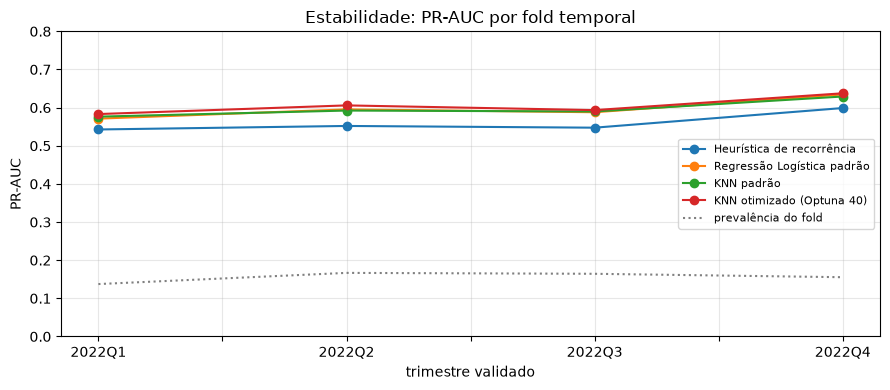

,Heurística de recorrência,Regressão Logística padrão,KNN padrão,KNN otimizado (Optuna 40),prevalência do fold
2022Q1,0.543,0.571,0.576,0.583,0.137
2022Q2,0.552,0.595,0.592,0.606,0.167
2022Q3,0.547,0.588,0.590,0.593,0.164
2022Q4,0.599,0.635,0.629,0.638,0.155
desvio (ddof=0),0.023,0.023,0.020,0.020,0.012


In [14]:
def por_fold(pipe=None, score=None):
    """PR-AUC em cada fold temporal (o _cv só devolve média e desvio)."""
    saida = []
    for tr, te in folds:
        s = score.iloc[te] if score is not None else clone(pipe).fit(Xtr.iloc[tr], ytr.iloc[tr]).predict_proba(Xtr.iloc[te])[:, 1]
        saida.append(average_precision_score(ytr.iloc[te], s))
    return saida


rotulos = [tri_tr[te][0] for _, te in folds]
folds_df = pd.DataFrame({
    NOMES["heuristica_recorrencia"]: por_fold(score=score_heuristica(partes["treino"])),
    NOMES["regressao_logistica"]: por_fold(montar_pipeline(features, "regressao_logistica")),
    NOMES["knn_padrao"]: por_fold(montar_pipeline(features, MODELO)),
    NOMES["knn_otimizado"]: por_fold(pipe_otim),
    "prevalência do fold": [ytr.iloc[te].mean() for _, te in folds],
}, index=rotulos)
fig, ax = plt.subplots(figsize=(9, 4))
folds_df.iloc[:, :4].plot(ax=ax, marker="o")
folds_df["prevalência do fold"].plot(ax=ax, color="gray", ls=":", label="prevalência do fold")
ax.set(xlabel="trimestre validado", ylabel="PR-AUC", ylim=(0, .8), title="Estabilidade: PR-AUC por fold temporal")
ax.legend(fontsize=8)
salvar(fig, "pr_auc_por_fold.png")
folds_df.loc["desvio (ddof=0)"] = folds_df.std(ddof=0)
folds_df.round(3)

**Leitura.** O KNN otimizado fica **acima da Regressão Logística nos 4 folds**, mas por pouco:
+0,012, +0,011, +0,005 e +0,003 (2022Q1 a 2022Q4). Fica acima da heurística em todos, por +0,039 a
+0,054. O desvio entre folds é 0,020, contra 0,023 dos dois pisos. Os quatro modelos sobem e descem
juntos (o 2022Q4 é o trimestre mais fácil para todos), então a variação entre folds vem mais do
trimestre do que do modelo. A vantagem sobre a Regressão Logística diminui conforme o treino do fold
cresce, mas, com 4 pontos, isso não passa de observação. O KNN padrão fica colado na Regressão
Logística em todos os folds (de −0,006 a +0,005).

## 7. Análise própria do KNN

**PR-AUC da CV temporal em função de `n_neighbors`**, com uma curva para cada `weights`. Inclui
k = 5, abaixo do espaço de busca, só como referência do lado de alta variância. Esta varredura
não escolhe nada (a escolha já foi feita pela busca) e não é registrada no MLflow.

varredura (14 configurações × 4 folds) em 14.5 s


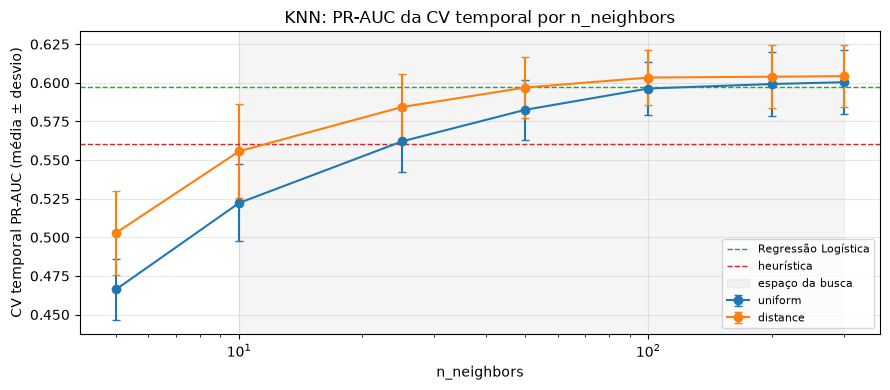

cv_temporal_pr_auc_mean         cv_temporal_pr_auc_std        
weights                    distance uniform               distance uniform
n_neighbors                                                               
5                             0.503   0.466                  0.027   0.020
10                            0.556   0.522                  0.030   0.025
25                            0.584   0.562                  0.022   0.020
50                            0.597   0.583                  0.020   0.019
100                           0.603   0.596                  0.018   0.017
200                           0.604   0.599                  0.020   0.021
300                           0.604   0.600                  0.020   0.021

In [15]:
KS_GRADE = [5, 10, 25, 50, 100, 200, 300]
t0 = time.time()
grade = pd.DataFrame([{"n_neighbors": k, "weights": w,
                       **_cv(montar_pipeline(features, MODELO, n_neighbors=k, weights=w), Xtr, ytr, folds)}
                      for w in ("uniform", "distance") for k in KS_GRADE])
print(f"varredura ({len(grade)} configurações × {len(folds)} folds) em {time.time() - t0:.1f} s")

fig, ax = plt.subplots(figsize=(9, 4))
for w, cor in [("uniform", "C0"), ("distance", "C1")]:
    g = grade[grade["weights"] == w]
    ax.errorbar(g["n_neighbors"], g["cv_temporal_pr_auc_mean"], yerr=g["cv_temporal_pr_auc_std"], marker="o",
                capsize=3, color=cor, label=w)
ax.axhline(r_lr["cv_temporal_pr_auc_mean"], color="C2", ls="--", lw=1, label="Regressão Logística")
ax.axhline(r_h["cv_temporal_pr_auc_mean"], color="C3", ls="--", lw=1, label="heurística")
ax.axvspan(10, 300, color="gray", alpha=.08, label="espaço da busca")
ax.set(xscale="log", xlabel="n_neighbors", ylabel="CV temporal PR-AUC (média ± desvio)",
       title="KNN: PR-AUC da CV temporal por n_neighbors")
ax.legend(fontsize=8)
salvar(fig, "pr_auc_por_n_neighbors.png")
grade.pivot(index="n_neighbors", columns="weights", values=["cv_temporal_pr_auc_mean", "cv_temporal_pr_auc_std"]).round(4)

**Leitura (viés × variância).**

- **k pequeno = variância alta.** Com k = 5, o PR-AUC é 0,503 (`distance`) e 0,466 (`uniform`),
  abaixo da heurística (0,560). O desvio entre folds também é o maior (0,027 e 0,020; 0,030 com k =
  10). O score de cada local depende de poucos vizinhos, e um vizinho a mais ou a menos muda muito
  a ordem.
- **Aumentar k suaviza e melhora até ~100**: 0,556 → 0,584 → 0,597 → 0,603 (`distance`, k = 10 a
  100). Depois disso, a curva fica plana (0,604 com k = 200 e 300), e o desvio fica em 0,018 a 0,020.
- **O lado do viés não aparece até k = 300.** Um k grande demais faria a vizinhança perder o
  caráter local e puxaria todos os scores para a prevalência, o que derrubaria o PR-AUC. Com 300
  vizinhos (2,2% das 13.384 linhas do treino, 4,5% do menor treino de fold), isso ainda não
  acontece. Os locais de risco formam regiões grandes no espaço das features, o que é coerente com
  o sinal vir de poucas variáveis de histórico (ver a permutação abaixo).
- **`distance` ganha de `uniform` em todo k**, mas a diferença cai de 0,037 (k = 5) para 0,004 (k =
  300). Com k pequeno, o peso pela distância compensa parte do ruído. Com k grande, os vizinhos
  distantes pesam pouco nos dois casos.
- Com k ≥ 50 e `distance`, o KNN alcança a Regressão Logística (0,597). Ele não passa dela por mais
  do que um desvio.

**Valores de score distintos e empates na validação**, `uniform` × `distance`, para os mesmos k.
Cada configuração é ajustada no treino inteiro e prevista na validação de 2023; o PR-AUC e o
Recall@50 da validação vêm junto só como referência.

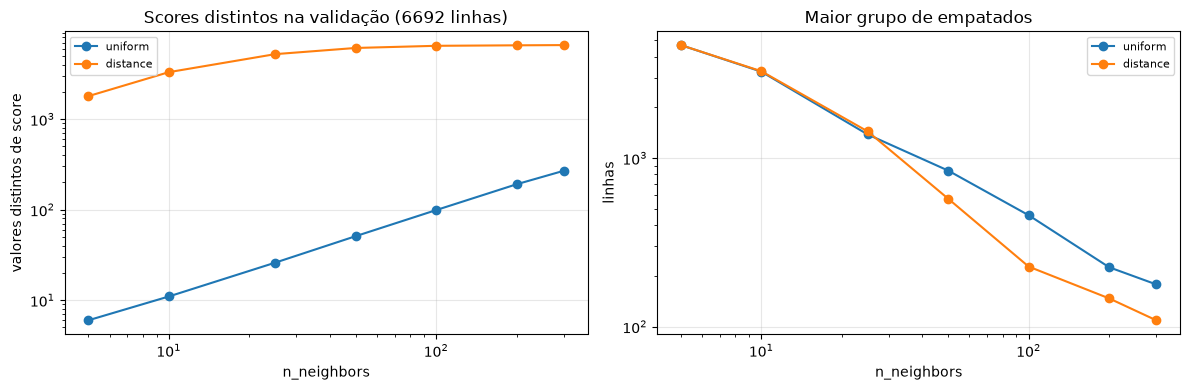

,weights,n_neighbors,scores distintos,maior grupo empatado,score do maior grupo,empatados com o 50º (média por trimestre),Val PR-AUC,Val Recall@50
0,uniform,5,6,4686,0.000,53.50,0.544,0.137
1,uniform,10,11,3259,0.000,24.50,0.589,0.134
2,uniform,25,26,1381,0.000,10.25,0.623,0.139
3,uniform,50,51,843,0.040,5.75,0.642,0.139
4,uniform,100,99,458,0.040,4.00,0.643,0.138
5,uniform,200,191,225,0.060,1.75,0.648,0.140
6,uniform,300,269,178,0.073,2.00,0.650,0.139
7,distance,5,1796,4686,0.000,41.25,0.576,0.137
8,distance,10,3306,3278,0.000,1.00,0.626,0.136
9,distance,25,5228,1440,0.000,1.00,0.646,0.138


In [16]:
linhas_emp = []
for w in ("uniform", "distance"):
    for k in KS_GRADE:
        s = montar_pipeline(features, MODELO, n_neighbors=k, weights=w).fit(Xtr, ytr).predict_proba(Xv)[:, 1]
        linhas_emp.append({"weights": w, "n_neighbors": k, **empates(s, tri_v), "Val PR-AUC": average_precision_score(yv, s),
                           "Val Recall@50": metricas.no_topo(yv, s, tri_v, 50)[0]})
emp = pd.DataFrame(linhas_emp)
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for w, cor in [("uniform", "C0"), ("distance", "C1")]:
    g = emp[emp["weights"] == w]
    axs[0].plot(g["n_neighbors"], g["scores distintos"], "o-", color=cor, label=w)
    axs[1].plot(g["n_neighbors"], g["maior grupo empatado"], "o-", color=cor, label=w)
axs[0].set(xscale="log", yscale="log", xlabel="n_neighbors", ylabel="valores distintos de score",
           title=f"Scores distintos na validação ({len(Xv)} linhas)")
axs[1].set(xscale="log", yscale="log", xlabel="n_neighbors", ylabel="linhas", title="Maior grupo de empatados")
for ax in axs:
    ax.legend(fontsize=8)
salvar(fig, "empates_uniform_distance.png")
emp.round(3)

**Leitura.**

- Com **`uniform`**, o score é (positivos entre os k vizinhos) / k e só tem até k + 1 valores: 6 com
  k = 5, 51 com k = 50 e 269 com k = 300. Com k = 5, 4.686 das 6.692 linhas (70%) empatam em 0, e
  em média 53,5 linhas por trimestre empatam com o 50º colocado. Nesse caso, o Recall@50 depende da
  ordem das linhas na tabela. Com k = 50, ainda são 5,75 por trimestre no corte.
- Com **`distance`**, o score é contínuo: de 1.796 valores distintos (k = 5) a 6.580 (k = 300). A
  partir de k = 10, só 1 linha tem o score do 50º colocado, ou seja, não há empate no corte. O
  maior grupo empatado continua em 0 (locais sem positivo na vizinhança), mas fica no fim da lista e
  encolhe com k (de 4.686 com k = 5 para 109 com k = 300).
- O efeito sobre o Recall@50 na validação ficou pequeno: de 0,134 a 0,140 em todas as 14
  configurações. Com k pequeno e `uniform`, porém, esse número é parcialmente arbitrário (depende do
  desempate). O PR-AUC na validação sobe com k nos dois casos (`uniform` de 0,544 a 0,650 e
  `distance` de 0,576 a 0,656), como na CV temporal. Este é mais um motivo para `distance`.

**Custo computacional.** O KNN não aprende parâmetros: o `fit` só guarda o treino (e monta a
estrutura de busca, se houver). O custo vai para a predição: com `algorithm="brute"`, cada linha
prevista calcula a distância para todas as linhas do treino, então o tempo cresce com
(linhas previstas) × (linhas de treino) × (colunas). Meço o tempo de ajuste e de predição na
validação, ao lado da Regressão Logística, e a predição com treinos de 2, 4, 6 e 8 trimestres
(janela crescente, como os folds), para ver o crescimento. Cada medida é a mediana de 3 repetições.

,ajuste (s),predição na validação (s),predição por 1.000 linhas (ms)
Regressão Logística padrão,2.219,0.078,11.611
KNN padrão,0.150,0.739,110.464
KNN otimizado (Optuna 40),0.144,0.908,135.683


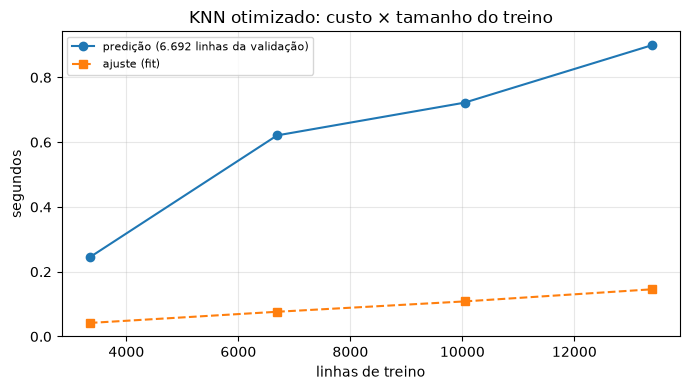

,trimestres de treino,linhas de treino,ajuste (s),predição na validação (s)
0,2,3346,0.042,0.245
1,4,6692,0.076,0.621
2,6,10038,0.108,0.722
3,8,13384,0.146,0.899


In [17]:
def cronometrar(pipe, Xa, ya, Xp, rep=3):
    tf, tp = [], []
    for _ in range(rep):
        p = clone(pipe)
        t0 = time.perf_counter(); p.fit(Xa, ya); tf.append(time.perf_counter() - t0)
        t0 = time.perf_counter(); p.predict_proba(Xp); tp.append(time.perf_counter() - t0)
    return float(np.median(tf)), float(np.median(tp))


custo = {}
for nome, pipe in [(NOMES["regressao_logistica"], montar_pipeline(features, "regressao_logistica")),
                   (NOMES["knn_padrao"], montar_pipeline(features, MODELO)),
                   (NOMES["knn_otimizado"], pipe_otim)]:
    tf, tp = cronometrar(pipe, Xtr, ytr, Xv)
    custo[nome] = {"ajuste (s)": tf, "predição na validação (s)": tp, "predição por 1.000 linhas (ms)": 1000 * tp / len(Xv) * 1000}
display(pd.DataFrame(custo).T.round(3))

tris = np.sort(pd.unique(tri_tr))
escala = []
for n in (2, 4, 6, 8):
    sel = np.isin(tri_tr, tris[:n])
    tf, tp = cronometrar(pipe_otim, Xtr[sel], ytr[sel], Xv)
    escala.append({"trimestres de treino": n, "linhas de treino": int(sel.sum()), "ajuste (s)": tf, "predição na validação (s)": tp})
escala = pd.DataFrame(escala)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(escala["linhas de treino"], escala["predição na validação (s)"], "o-", label="predição (6.692 linhas da validação)")
ax.plot(escala["linhas de treino"], escala["ajuste (s)"], "s--", label="ajuste (fit)")
ax.set(xlabel="linhas de treino", ylabel="segundos", title=f"KNN otimizado: custo × tamanho do treino", ylim=(0, None))
ax.legend(fontsize=8)
salvar(fig, "custo_por_tamanho_treino.png")
escala.round(3)

**Leitura.**

- **O custo do KNN está na predição, não no ajuste.** O `fit` do KNN otimizado leva 0,14 s (só o
  pré-processamento e guardar o treino), contra 2,2 s da Regressão Logística. A predição das 6.692
  linhas da validação leva 0,91 s, contra 0,08 s: cerca de 12 vezes mais (136 ms contra 12 ms por
  1.000 linhas). O KNN padrão (k = 50) prevê em 0,74 s; com k = 221, a predição fica um pouco mais cara.
- **O tempo de predição cresce com o tamanho do treino**: de 3.346 para 13.384 linhas (4×), ele vai
  de 0,25 s para 0,90 s (3,7×), quase linear, como se espera da busca `brute`, que compara cada linha
  prevista com todas as do treino. Ele também cresce com o número de linhas previstas e de colunas.
  O retreino em treino + validação (cerca de 20 mil linhas) deixaria cada predição cerca de 1,5 vez
  mais lenta.
- Nesta escala, os valores absolutos são pequenos: o scoring semanal de 1.673 locais é trivial. O
  custo pesa nas rotinas que preveem muitas vezes. A busca de 40 trials (160 ajustes e predições)
  levou 46 s, e a importância por permutação (48 colunas × 5 repetições, todas predições), 231 s.
  Esta foi a etapa mais cara do notebook.

**Importância por permutação** na validação de 2023 (`metricas.importancia_permutacao`: queda média
de PR-AUC ao embaralhar cada coluna original, 5 repetições, semente 42), top 15. O KNN não tem
`feature_importances_` nem coeficientes, então esta é a única leitura de quais atributos pesam.

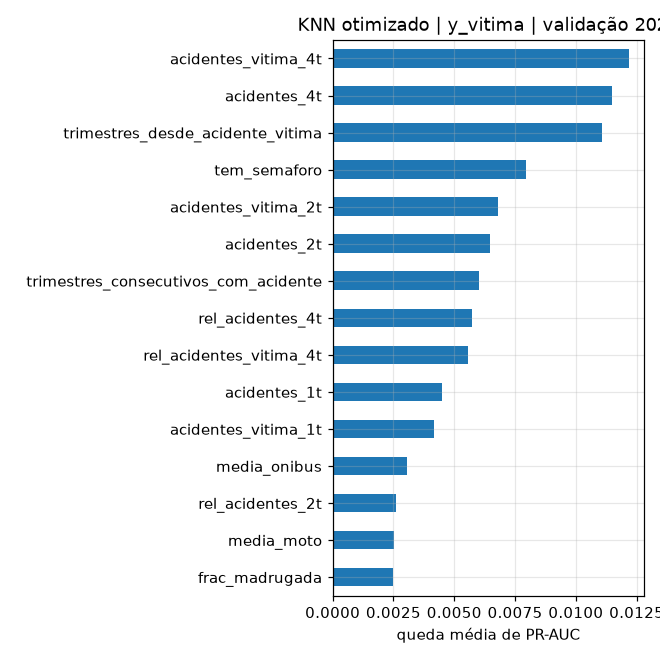

tempo da permutação: 231.1 s (48 colunas × 5 repetições)
atributos com queda de PR-AUC > 0: 40 de 48 | com queda < 0: 7


,queda média de PR-AUC
acidentes_vitima_4t,0.012
acidentes_4t,0.011
trimestres_desde_acidente_vitima,0.011
tem_semaforo,0.008
acidentes_vitima_2t,0.007
acidentes_2t,0.006
trimestres_consecutivos_com_acidente,0.006
rel_acidentes_4t,0.006
rel_acidentes_vitima_4t,0.006
acidentes_1t,0.004


In [18]:
t0 = time.time()
_, imp_perm = metricas.importancia_permutacao(pipe_otim, Xv, yv, FIG / "permutation_importance.png",
                                              f"{titulo_otim} | validação 2023", top=15)
tempo_perm = time.time() - t0
display(Image(FIG / "permutation_importance.png"))
print(f"tempo da permutação: {tempo_perm:.1f} s ({Xv.shape[1]} colunas × 5 repetições)")
print(f"atributos com queda de PR-AUC > 0: {(imp_perm > 0).sum()} de {len(imp_perm)} | com queda < 0: {(imp_perm < 0).sum()}")
imp_perm.head(15).round(4).to_frame("queda média de PR-AUC")

**Leitura.**

- As quedas são **pequenas e espalhadas**. A maior é 0,012 de PR-AUC (`acidentes_vitima_4t`), e
  40 das 48 colunas têm queda positiva. O KNN usa todas as 142 colunas na distância. Embaralhar uma
  coluna só muda um pouco a vizinhança, e as colunas de histórico são correlacionadas entre si (uma
  cobre a outra). Por isso, nenhuma coluna aparece isolada no topo.
- O topo é **histórico recente do local**: `acidentes_vitima_4t` (0,012), `acidentes_4t` (0,011),
  `trimestres_desde_acidente_vitima` (0,011), `acidentes_vitima_2t`, `acidentes_2t`,
  `trimestres_consecutivos_com_acidente` e as participações relativas de 4 trimestres (0,006 a
  0,007). É, em essência, a mesma informação da heurística de recorrência. Fora do histórico,
  aparecem `tem_semaforo` (0,008, a 4ª maior), `media_onibus`, `media_moto` e `frac_madrugada`
  (0,003).
- 7 colunas têm queda **negativa**: embaralhá-las melhora levemente o PR-AUC na validação. São
  colunas que só acrescentam ruído à distância. Do 5º lugar em diante, as diferenças (0,003 a 0,007)
  são pequenas demais para ordenar com confiança.

## 8. Erros na validação de 2023

Os 10 maiores falsos positivos (sem acidente com vítima no trimestre seguinte, mas com os maiores
scores) e os 10 maiores falsos negativos (com acidente, mas com os menores scores), da melhor
configuração. `trimestre` é o trimestre da linha (das features); o alvo é o trimestre seguinte.

In [19]:
from src.comum.db import engine

dim = pd.read_sql_table("dim_local", engine())[["local_id", "bairro", "logradouro"]]
score_otim = pipe_otim.predict_proba(Xv)[:, 1]
erros = (partes["validacao"][["local_id", "trimestre", "acidentes_vitima_4t", "acidentes_4t", ALVO]]
         .assign(score=score_otim).merge(dim, on="local_id", how="left"))
erros["trimestre_alvo"] = (pd.PeriodIndex(erros["trimestre"], freq="Q") + 1).astype(str)
colunas = ["bairro", "logradouro", "trimestre", "trimestre_alvo", "score", "acidentes_vitima_4t", "acidentes_4t"]
fp = erros[erros[ALVO] == 0].sort_values("score", ascending=False, kind="stable")
fn = erros[erros[ALVO] == 1].sort_values("score", kind="stable")
print(f"limiar (F1 na validação): {m_otim['limiar']:.4f} | FP: {int(m_otim['fp'])} | FN: {int(m_otim['fn'])}")
print(f"negativos empatados no maior score ({fp['score'].iloc[0]:.4f}): {(fp['score'] == fp['score'].iloc[0]).sum()} | "
      f"positivos empatados no menor score ({fn['score'].iloc[0]:.4f}): {(fn['score'] == fn['score'].iloc[0]).sum()}")
print("\n10 maiores falsos positivos")
display(fp[colunas].head(10).reset_index(drop=True))
print("10 maiores falsos negativos")
display(fn[colunas].head(10).reset_index(drop=True))
print("histórico médio (acidentes_vitima_4t) | todos os negativos:",
      round(erros.loc[erros[ALVO] == 0, "acidentes_vitima_4t"].mean(), 2),
      "| todos os positivos:", round(erros.loc[erros[ALVO] == 1, "acidentes_vitima_4t"].mean(), 2))
print("positivos com acidentes_4t == 0:", int(((erros[ALVO] == 1) & (erros["acidentes_4t"] == 0)).sum()),
      "de", int(erros[ALVO].sum()))

limiar (F1 na validação): 0.2319 | FP: 560 | FN: 586
negativos empatados no maior score (0.8443): 1 | positivos empatados no menor score (0.0000): 9

10 maiores falsos positivos


,bairro,logradouro,trimestre,trimestre_alvo,score,acidentes_vitima_4t,acidentes_4t
0,SÃO JOSÉ,RUA IMPERIAL,2023Q1,2023Q2,0.844,12,17
1,CAMPO GRANDE,RUA ODORICO MENDES,2023Q3,2023Q4,0.842,16,16
2,DOIS IRMÃOS,RUA MANUEL DE MEDEIROS,2023Q4,2024Q1,0.826,18,18
3,TEJIPIÓ,AV DR JOSE RUFINO,2023Q2,2023Q3,0.811,12,14
4,BOA VIAGEM,RUA RIBEIRO DE BRITO,2023Q1,2023Q2,0.807,10,12
5,BOA VIAGEM,RUA ANTONIO FALCAO,2023Q4,2024Q1,0.754,7,7
6,BOA VIAGEM,RUA BARAO DE SOUZA LEAO,2023Q1,2023Q2,0.746,6,8
7,BOA VISTA,AV GOVERNADOR AGAMENON MAGALHAES,2023Q1,2023Q2,0.741,10,15
8,DOIS UNIDOS,AV HILDEBRANDO DE VASCONCELOS,2023Q3,2023Q4,0.723,8,10
9,ARRUDA,RUA DAS MOCAS,2023Q4,2024Q1,0.713,7,10


10 maiores falsos negativos


,bairro,logradouro,trimestre,trimestre_alvo,score,acidentes_vitima_4t,acidentes_4t
0,CASA AMARELA,RUA FERREIRA LOPES,2023Q1,2023Q2,0.000,0,0
1,AFOGADOS,RUA TABAIARES,2023Q1,2023Q2,0.000,0,0
2,ENGENHO DO MEIO,AV VISCONDE DE SAO LEOPOLDO,2023Q2,2023Q3,0.000,0,0
3,JOANA BEZERRA,AV ADVOGADO JOSE PAULO CAVALCANTI,2023Q2,2023Q3,0.000,0,0
4,TOTÓ,RUA JUVENCIO MARQUES DA CUNHA,2023Q2,2023Q3,0.000,0,0
5,SOLEDADE,RUA DO PRINCIPE,2023Q2,2023Q3,0.000,0,0
6,IPUTINGA,RUA PADRE FERNAO CARDIM,2023Q3,2023Q4,0.000,0,0
7,AFLITOS,RUA DO FUTURO,2023Q3,2023Q4,0.000,0,0
8,PAISSANDU,AV ENGENHEIRO AGAMENON DE MAGALHAES MELO,2023Q4,2024Q1,0.000,0,0
9,CORDEIRO,RUA VISCONDE DE ITABORAI,2023Q3,2023Q4,0.004,0,0


histórico médio (acidentes_vitima_4t) | todos os negativos: 0.47 | todos os positivos: 4.83
positivos com acidentes_4t == 0: 315 de 1392


**Leitura.** No limiar que maximiza o F1 na validação (0,232), são 560 falsos positivos e 586 falsos
negativos. Os empates quase não pesam aqui: só 1 negativo tem o maior score (0,844), e 9 positivos
empatam no menor (0,000). Os 10 de cada lado são, então, de fato os extremos (só a ordem entre os 9
positivos com score 0 é arbitrária).

- **Falsos positivos:** locais com histórico alto (6 a 18 acidentes com vítima nos últimos 4
  trimestres), como a Rua Imperial (São José, 12 de 17), a Rua Manuel de Medeiros (Dois Irmãos, 18
  de 18) e a Av. Governador Agamenon Magalhães (Boa Vista, 10 de 15), que não tiveram acidente com
  vítima no trimestre seguinte. É o erro natural de um ranking por recorrência: um trimestre sem
  registro num local que costuma ter acidentes.
- **Falsos negativos:** todos têm **zero** acidentes nos últimos 4 trimestres e score 0 ou quase 0
  (nenhum vizinho positivo). Entre os 1.392 positivos da validação, 315 (23%) vêm de locais sem
  nenhum acidente nos 4 trimestres anteriores, e nenhum modelo baseado nestas features consegue
  separá-los dos outros locais "quietos". A média de `acidentes_vitima_4t` é 4,83 nos positivos e
  0,47 nos negativos: o modelo acerta a tendência, mas não antecipa o primeiro acidente de um local.

## 9. Alvo secundário: `y_atropelamento`

A melhor configuração (escolhida em `y_vitima`) reavaliada em `y_atropelamento`, com as mesmas
partes e os mesmos folds temporais, ao lado dos pisos e do KNN padrão. Ressalva
(`ARCHITECTURE.md`, seção 17.2): o alvo tem pouquíssimos positivos (cerca de 30 a 50 por
trimestre), então o PR-AUC de cada fold oscila muito e diferenças pequenas não querem dizer nada.

No MLflow, só a melhor configuração reavaliada vira run (experimento 03, `busca=optuna_40`,
`alvo=y_atropelamento`). Os pisos e o padrão neste alvo são calculados sem registro.

In [20]:
ALVO2 = "y_atropelamento"
partes2, folds2 = preparar(ALVO2)
Xtr2, ytr2 = _xy(partes2["treino"], ALVO2)
Xv2, yv2 = _xy(partes2["validacao"], ALVO2)
tri2 = partes2["treino"]["trimestre"].to_numpy()
print(f"positivos: treino {ytr2.sum()} ({ytr2.mean():.4f}) | validação {yv2.sum()} ({yv2.mean():.4f})")
print("positivos na validação de cada fold:", {tri2[te][0]: int(ytr2.iloc[te].sum()) for _, te in folds2})
print("positivos por trimestre na validação 2023:", partes2["validacao"].groupby("trimestre")[ALVO2].sum().to_dict())

for nome, r in pisos(ALVO2, partes2, folds2).items():
    resultados[(ALVO2, nome)] = r
pad2 = montar_pipeline(features, MODELO)
cv_pad2 = {**_cv(pad2, Xtr2, ytr2, folds2), **_cv_estratificado(pad2, Xtr2, ytr2)}
resultados[(ALVO2, "knn_padrao")] = linha(
    cv_pad2, em_validacao(yv2, clone(pad2).fit(Xtr2, ytr2).predict_proba(Xv2)[:, 1], partes2["validacao"]["trimestre"]))

pipe_otim2 = montar_pipeline(features, MODELO, **params_melhor)
cv_otim2 = {**_cv(pipe_otim2, Xtr2, ytr2, folds2), **_cv_estratificado(pipe_otim2, Xtr2, ytr2)}
run_otim2, m_otim2 = _rodar(f"{MODELO}_optuna40_melhor", ALVO2, pipe_otim2, partes2, params_melhor, cv_otim2,
                            {"etapa": "otimizacao", "busca": "optuna_40", **TAGS}, folds2)
resultados[(ALVO2, "knn_otimizado")] = linha(cv_otim2, m_otim2, run_otim2)
print("run", run_otim2)
print("empates do KNN otimizado na validação:", empates(pipe_otim2.predict_proba(Xv2)[:, 1], partes2["validacao"]["trimestre"]))
tabela(ALVO2, ["heuristica_recorrencia", "regressao_logistica", "knn_padrao", "knn_otimizado"])

positivos: treino 313 (0.0234) | validação 151 (0.0226)


positivos na validação de cada fold: {'2022Q1': 46, '2022Q2': 48, '2022Q3': 44, '2022Q4': 42}
positivos por trimestre na validação 2023: {'2023Q1': 40.0, '2023Q2': 40.0, '2023Q3': 36.0, '2023Q4': 35.0}


2026/11/23 14:39:34 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


🏃 View run knn_optuna40_melhor at: http://mlflow:5000/#/experiments/2/runs/83f948783e1d4a4aac31077f0361e97f
🧪 View experiment at: http://mlflow:5000/#/experiments/2
run 83f948783e1d4a4aac31077f0361e97f


empates do KNN otimizado na validação: {'scores distintos': 4882, 'maior grupo empatado': 1810, 'score do maior grupo': 0.0, 'empatados com o 50º (média por trimestre)': 1.0}


,CV temporal PR-AUC,CV temporal ROC-AUC,CV estratificado PR-AUC,Δ PR-AUC estrat. − temporal,Val PR-AUC,Val Recall@50,Val Recall@100,Val ROC-AUC
Heurística de recorrência,0.318 ± 0.016,0.841 ± 0.023,0.272 ± 0.050,-0.046,0.290,0.424,0.562,0.828
Regressão Logística padrão,0.303 ± 0.018,0.818 ± 0.013,0.274 ± 0.064,-0.029,0.278,0.418,0.558,0.823
KNN padrão,0.313 ± 0.020,0.852 ± 0.028,0.269 ± 0.050,-0.044,0.309,0.439,0.597,0.835
KNN otimizado (Optuna 40),0.332 ± 0.026,0.867 ± 0.030,0.282 ± 0.055,-0.049,0.309,0.425,0.597,0.840


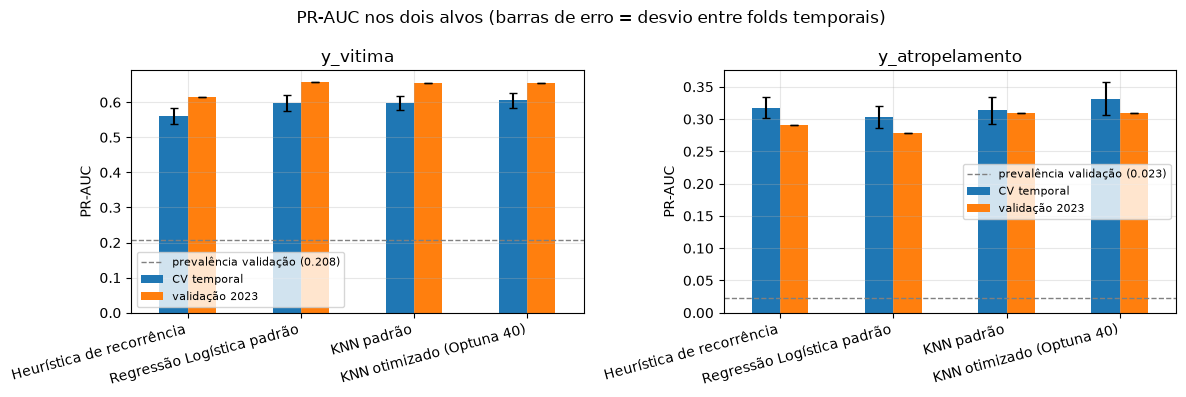

In [21]:
ordem = ["heuristica_recorrencia", "regressao_logistica", "knn_padrao", "knn_otimizado"]
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for ax, alvo, prev in [(axs[0], ALVO, yv.mean()), (axs[1], ALVO2, yv2.mean())]:
    vals = pd.DataFrame({NOMES[n]: {"CV temporal": resultados[(alvo, n)]["cv_temporal_pr_auc_mean"],
                                    "validação 2023": resultados[(alvo, n)]["val_pr_auc"]} for n in ordem}).T
    erro = pd.DataFrame({"CV temporal": [resultados[(alvo, n)]["cv_temporal_pr_auc_std"] for n in ordem],
                         "validação 2023": 0}, index=vals.index)
    vals.plot.bar(ax=ax, yerr=erro, capsize=3)
    ax.axhline(prev, color="gray", ls="--", lw=1, label=f"prevalência validação ({prev:.3f})")
    ax.set(title=alvo, ylabel="PR-AUC")
    ax.legend(fontsize=8)
    plt.setp(ax.get_xticklabels(), rotation=15, ha="right")
fig.suptitle("PR-AUC nos dois alvos (barras de erro = desvio entre folds temporais)")
salvar(fig, "pr_auc_dois_alvos.png")

**Leitura** (com a ressalva da seção 17.2: de 42 a 48 positivos por fold, de 35 a 40 por trimestre de
2023 e 151 na validação inteira).

- O **KNN otimizado tem o maior PR-AUC** nos dois recortes: 0,332 ± 0,026 na CV temporal, contra
  0,318 ± 0,016 da heurística (+0,014) e 0,303 ± 0,018 da Regressão Logística (+0,029). Na
  validação, são 0,309 contra 0,290 (+0,019) e 0,278 (+0,031). O KNN padrão também dá 0,309 na
  validação. O Recall@100 na validação é 0,597, contra 0,562 e 0,558. O Recall@50 empata (0,425,
  contra 0,424 e 0,418). O ROC-AUC é o maior (0,867 na CV e 0,840 na validação).
- **Essas diferenças não são conclusivas.** A vantagem sobre a heurística (+0,014 na CV) é menor que
  o desvio entre folds (0,016 a 0,026), e cada trimestre tem só 35 a 48 positivos. O que se pode
  dizer é que a direção é a mesma na CV e na validação, e que o KNN não perde para os pisos neste
  alvo.
- Os hiperparâmetros vieram da busca em `y_vitima`. Não houve busca própria para este alvo, então
  este resultado mede a transferência da configuração. O k-fold estratificado de novo dá menos que a
  CV temporal (−0,029 a −0,049). O score tem 1.810 linhas empatadas em 0 (locais sem atropelamento
  na vizinhança), mas só 1 no corte do 50º.

## 10. Tabela final e exportação

In [22]:
NOMES_ALVO = {"y_vitima": "y_vitima (principal)", "y_atropelamento": "y_atropelamento (secundário)"}
tabela2 = pd.concat({NOMES_ALVO[a]: tabela(a, ordem) for a in (ALVO, ALVO2)})
tabela2.index.names = ["alvo", "modelo"]
tabela2

CV temporal PR-AUC CV temporal ROC-AUC CV estratificado PR-AUC Δ PR-AUC estrat. − temporal Val PR-AUC Val Recall@50  \
alvo                         modelo                                                                                                                                           
y_vitima (principal)         Heurística de recorrência       0.560 ± 0.023       0.790 ± 0.016           0.541 ± 0.021                      -0.019      0.614         0.141   
                             Regressão Logística padrão      0.597 ± 0.023       0.816 ± 0.017           0.578 ± 0.020                      -0.019      0.658         0.141   
                             KNN padrão                      0.597 ± 0.020       0.823 ± 0.013           0.573 ± 0.026                      -0.024      0.656         0.139   
                             KNN otimizado (Optuna 40)       0.605 ± 0.020       0.826 ± 0.015           0.581 ± 0.024                      -0.024      0.654         0.140   
y_atropelamento (secundário) Heurística de recorrência       0.318 ± 0.016       0.841 ± 0.023           0.272 ± 0.050                      -0.046      0.290         0.424   
                             Regressão Logística padrão      0.303 ± 0.018       0.818 ± 0.013           0.274 ± 0.064                      -0.029      0.278         0.418   
                             KNN padrão                      0.313 ± 0.020       0.852 ± 0.028           0.269 ± 0.050                      -0.044      0.309         0.439   
                             KNN otimizado (Optuna 40)       0.332 ± 0.026       0.867 ± 0.030           0.282 ± 0.055                      -0.049      0.309         0.425   

                                                        Val Recall@100 Val ROC-AUC  
alvo                         modelo                                                 
y_vitima (principal)         Heurística de recorrência           0.261       0.795  
                             Regressão Logística padrão          0.264       0.818  
                             KNN padrão                          0.258       0.827  
                             KNN otimizado (Optuna 40)           0.262       0.826  
y_atropelamento (secundário) Heurística de recorrência           0.562       0.828  
                             Regressão Logística padrão          0.558       0.823  
                             KNN padrão                          0.597       0.835  
                             KNN otimizado (Optuna 40)           0.597       0.840

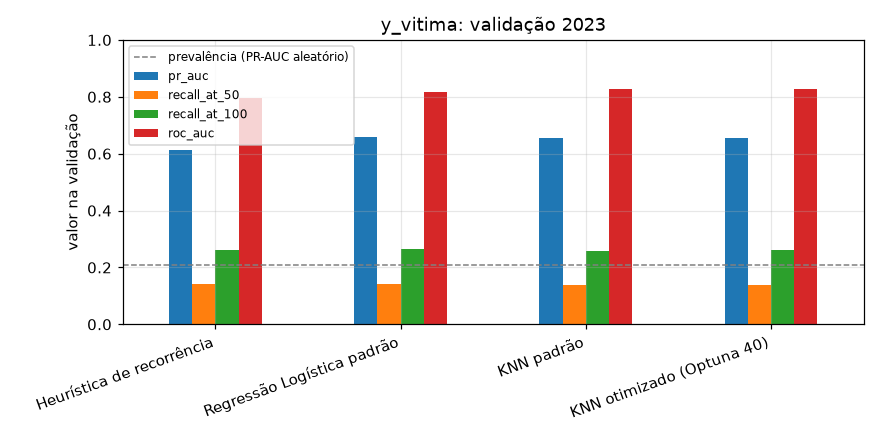

gravado: reports/experimentos/marina_knn.csv
figuras: ['comparacao_validacao_y_vitima.png', 'curva_aprendizado.png', 'custo_por_tamanho_treino.png', 'empates_uniform_distance.png', 'optuna_melhor_acumulado.png', 'optuna_pr_auc_por_hiperparametro.png', 'permutation_importance.png', 'pr_auc_dois_alvos.png', 'pr_auc_por_fold.png', 'pr_auc_por_n_neighbors.png', 'pr_auc_treino_validacao.png']


In [23]:
# mesmas colunas do marina_adaboost.csv (branch ml/adaboost), para os dois arquivos se juntarem
colunas_csv = ["cv_temporal_pr_auc_mean", "cv_temporal_pr_auc_std", "cv_temporal_roc_auc_mean", "cv_temporal_roc_auc_std",
               "cv_estratificado_pr_auc_mean", "cv_estratificado_pr_auc_std", "val_pr_auc", "val_recall_at_50",
               "val_recall_at_100", "val_roc_auc", "val_prevalencia", "val_limiar", "val_f1", "val_precisao", "val_recall"]
csv = pd.DataFrame([{"autor": AUTOR, "modelo_investigado": MODELO, "alvo": a, "configuracao": n,
                     **{c: resultados[(a, n)].get(c) for c in colunas_csv},
                     "params": str(params_melhor) if n == "knn_otimizado" else
                               ("pipeline.modelos()" if n != "heuristica_recorrencia" else "acidentes_vitima_4t + acidentes_4t/1000"),
                     "run_id_mlflow": resultados[(a, n)].get("run_id")}
                    for a in (ALVO, ALVO2) for n in ordem])
csv["tempo_busca_optuna_s"] = round(tempo_busca, 1)
csv["n_trials_optuna"] = n_feitos
csv.to_csv(EXP / f"{AUTOR}_{MODELO}.csv", index=False)

barras = pd.DataFrame({NOMES[n]: {k.removeprefix("val_"): resultados[(ALVO, n)][k] for k in
                                  ["val_pr_auc", "val_recall_at_50", "val_recall_at_100", "val_roc_auc", "val_prevalencia"]}
                       for n in ordem}).T
metricas.barras_comparacao(barras, FIG / "comparacao_validacao_y_vitima.png", f"{ALVO}: validação 2023")
display(Image(FIG / "comparacao_validacao_y_vitima.png"))
print("gravado:", (EXP / f"{AUTOR}_{MODELO}.csv").relative_to(RAIZ))
print("figuras:", sorted(p.name for p in FIG.glob("*.png")))

**Leitura.** Na validação de 2023 (`y_vitima`), a otimização não melhorou o KNN: o otimizado dá
0,654 de PR-AUC, contra 0,656 do padrão. O ganho da busca (+0,008) aparece só na CV temporal, onde
ela foi feita, e é menor que o desvio entre folds. As quatro barras de Recall@50 (0,139 a 0,141) e
de Recall@100 (0,258 a 0,264) são praticamente iguais. Na prática, o KNN, a Regressão Logística e a
heurística põem quase os mesmos locais no topo de cada trimestre. O KNN se destaca só no ROC-AUC
(0,826, contra 0,818 e 0,795), isto é, na ordenação do meio e do fim da lista, que importa menos
para a CTTU.

## Conclusões

- **Desempenho.** Em `y_vitima`, a melhor configuração (Optuna com 40 trials, escolhida pela CV
  temporal: `n_neighbors=221`, `weights="distance"`) tem PR-AUC de **0,605 ± 0,020** na CV temporal
  e **0,654** na validação de 2023, com Recall@50 de 0,140, Recall@100 de 0,262 e ROC-AUC de 0,826.
  O KNN padrão do repositório (k = 50, `distance`) já dá 0,597 e 0,656.
- **Contra a Regressão Logística: empate.** +0,008 de PR-AUC na CV temporal (0,605 contra 0,597),
  menos que o desvio entre folds (0,020), e −0,004 na validação (0,654 contra 0,658). Recall@50 de
  0,140 contra 0,141. O KNN fica acima nos 4 folds temporais, mas por 0,003 a 0,012.
- **Contra a heurística de recorrência: ganha no PR-AUC, empata no topo.** +0,045 na CV temporal
  (0,605 contra 0,560) e +0,040 na validação (0,654 contra 0,614), acima nos 4 folds. No Recall@50
  (0,140 contra 0,141) e no Recall@100 (0,262 contra 0,261), empata. O ganho está na ordem do resto
  da lista, não nos 50 ou 100 primeiros de cada trimestre.
- **Alvo secundário:** em `y_atropelamento`, o KNN otimizado tem o maior PR-AUC (0,332 na CV e 0,309
  na validação, contra 0,318 e 0,290 da heurística), mas a diferença fica dentro do ruído de 35 a 48
  positivos por trimestre.
- **Hiperparâmetros.** `distance` é melhor que `uniform` em todo k, e também evita empates no topo
  da lista. O PR-AUC sobe com k até ~100 e fica plano até 300. O melhor k (221) fica na parte de
  cima do espaço, perto da borda de 300, mas num platô. Ampliar de 10 para 40 trials custou 4,5
  vezes mais (46 s contra 10 s) e rendeu +0,0005. Não valeu.
- **Sem overfitting.** O PR-AUC de 1,000 no treino é artefato do `weights="distance"`. Sem o próprio
  ponto, o treino dá 0,576, abaixo da CV.
- **Custo.** O ajuste é instantâneo (0,14 s), mas a predição é cerca de 12 vezes mais lenta que a da
  Regressão Logística (0,91 s contra 0,08 s na validação) e cresce linearmente com o tamanho do
  treino. Nesta base, isso é pequeno no scoring, mas fez da importância por permutação a etapa mais
  cara (231 s).
- **Em resumo:** o KNN chega ao nível da Regressão Logística e supera a heurística no PR-AUC, mas
  não melhora o topo da lista, que é o que a CTTU usa. Com o mesmo resultado, a Regressão Logística
  é mais barata para prever e mais interpretável.